In [1]:
%load_ext autoreload
%autoreload 2

In [2]:
import os
import random
import sys
sys.path.append("/home/dev/pose/pose")

from config import get_cfg_defaults

In [3]:
%matplotlib inline
import math
import torch

from matplotlib import pyplot as plt
from torchvision.io import read_image
from torchvision.transforms.v2 import InterpolationMode
from torchvision.transforms.v2 import ToPILImage
from torchvision.transforms.v2.functional import affine

from torchvision.utils import draw_bounding_boxes
from torchvision.utils import draw_keypoints

to_pil = ToPILImage()

COLOR_MAGENTA = (255, 0, 255) # RGB
COLOR_CYAN = (0, 255, 255) # RGB
COLOR_YELLOW = (255, 255, 0) # RGB

cfg = get_cfg_defaults()

connectivity = [[15, 13], [13, 11], [16, 14], [14, 12], [11, 12], [5, 11],
                [6, 12], [5, 6], [5, 7], [6, 8], [7, 9], [8, 10], [1, 2],
                [0, 1], [0, 2], [1, 3], [2, 4], [3, 5], [4, 6]]

In [4]:
from data.dataset import CocoDataset

In [5]:
dataset = CocoDataset(anno_fname=cfg.DATA_TRAIN.ANNOTATION_FNAME,
                      image_dir=cfg.DATA_TRAIN.IMAGE_DIR,
                      nn_input_size=cfg.NN.INPUT_SIZE,
                      data_aug_cfg=cfg.DATA_TRAIN.DATA_AUG,
                      min_keypoints=cfg.DATA_COMMON.MIN_KEYPOINTS,
                      transform=None
                     )

2025-01-02 13:34:29.189 | INFO     | data.dataset:_init_coco_info:118 - Keypoints idx2name: dict_items([(0, 'nose'), (1, 'L-eye'), (2, 'R-eye'), (3, 'L-ear'), (4, 'R-ear'), (5, 'L-shder'), (6, 'R-shder'), (7, 'L-elb'), (8, 'R-elb'), (9, 'L-wrst'), (10, 'R-wrst'), (11, 'L-hip'), (12, 'R-hip'), (13, 'L-knee'), (14, 'R-knee'), (15, 'L-ankl'), (16, 'R-ankl')])
2025-01-02 13:34:31.129 | INFO     | data.dataset:__init__:53 - Annotation fname: /home/dev/data/coco/annotations/person_keypoints_train2017.json
2025-01-02 13:34:31.129 | INFO     | data.dataset:__init__:56 - NN input size(height, width): [256, 192]
2025-01-02 13:34:31.130 | INFO     | data.dataset:__init__:73 - Data augmentation: True
2025-01-02 13:34:31.207 | INFO     | data.dataset:__init__:81 - Num images: 118,287
2025-01-02 13:34:31.207 | INFO     | data.dataset:__init__:84 - Num raw annotations: 262,465
2025-01-02 13:34:34.860 | INFO     | data.dataset:__init__:104 - skip crowd: 5,212
2025-01-02 13:34:34.860 | INFO     | data.

2025-01-02 13:35:26.961 | DEBUG    | data.dataset:_half_body_transform:205 - half body transform part: upper
2025-01-02 13:35:26.962 | DEBUG    | data.dataset:__getitem__:147 - the image is half-body transformed.
2025-01-02 13:35:26.963 | DEBUG    | data.dataset:__getitem__:152 - the image is horizontally flipped.
2025-01-02 13:35:26.963 | DEBUG    | data.dataset:__getitem__:158 - rotate: 31.97, scale: 0.97
2025-01-02 13:35:26.966 | DEBUG    | transforms:crop_and_resize_image:42 - center: [tensor(443, dtype=torch.int32), tensor(149, dtype=torch.int32)]
2025-01-02 13:35:26.966 | DEBUG    | transforms:crop_and_resize_image:44 - bw, 380.3040989427335, 394, 886
2025-01-02 13:35:26.967 | DEBUG    | transforms:crop_and_resize_image:46 - bh, 287.6411712815598, 552, 298
2025-01-02 13:35:26.967 | DEBUG    | transforms:crop_and_resize_image:57 - original image size: torch.Size([3, 425, 640])
2025-01-02 13:35:26.967 | DEBUG    | transforms:crop_and_resize_image:58 - original box size: 394, 298
20

idx: 121011
Num keypoints: 0


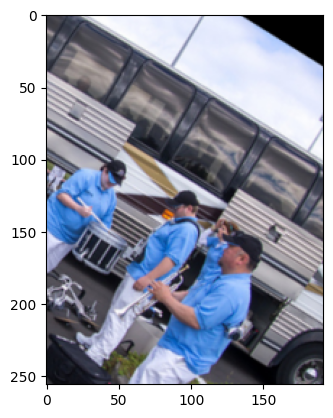

In [24]:
# idx = random.randint(0, len(dataset)-1)
idx = 121011
image, keypoints = dataset[idx]

print(f"idx: {idx}")
print(f"Num keypoints: {keypoints.num_visible()}")
kp = keypoints.get_kp().reshape(1,17,2)
vis = keypoints.get_vis().reshape(1,17)
image = draw_keypoints(image, kp, connectivity=connectivity, colors=COLOR_CYAN, radius=3, visibility=vis)
image = to_pil(image)
plt.imshow(image)
plt.show()

index: 121011


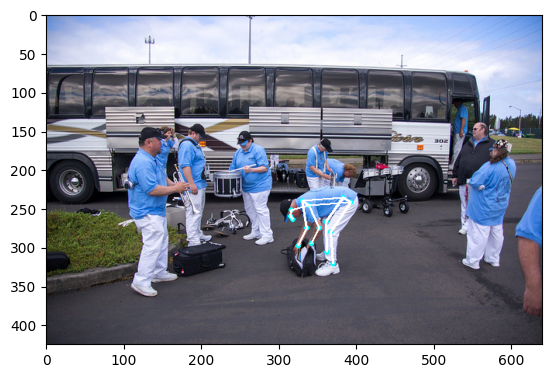

In [20]:
print(f"index: {idx}")
sample = dataset.get_sample(idx)
image_meta = dataset.get_image_meta(sample.image_id)
image_path = image_meta.fpath
image = read_image(image_path)
if image.shape[0] == 1:
    image = image.repeat(3, 1, 1)
keypoints = sample.keypoints
kp = keypoints.get_kp().reshape(1,17,2)
vis = keypoints.get_vis().reshape(1,17)
image = draw_keypoints(image, kp, connectivity=connectivity, colors=COLOR_CYAN, radius=3, visibility=vis)
image = to_pil(image)
plt.imshow(image)
plt.show()

보니까, upper, lower body transform 했을때만 이슈가 있네.

갑자기(?) 안되는 것들
- 121011
- 95267

너무 쏠렸는데
- 73037
- 62161

keypoint transform이 제대로 되지 않는 annotation index

## 까다로운 케이스들

(처리 필요) keypoint가 하나도 없는 경우
- 133155

(해결됨) 세로로 긴 샘플(특히 사진 왼쪽에 bbox가 붙어 있는 경우)에서는 잘 안 된다. (가운데 부분이 크랍되는 이슈)
- 126423
- 38328
- 77339

(해결됨) 좌우 사이드에 bbox가 붙어 있는 경우, 가운데 부분으로 확대돼서, cropped image만 보고서는 뭔지 가늠하기 어려운 경우가 있다. (위 이슈랑 어찌보면 같은 이슈)
- 111894
- 90045

(해결됨) 에러 발생했던 케이스들
- 133743

## 이상해보이는 데이터

color channel이 1개인 데이터가 있네.
- 86314

In [8]:
idx = 86314
sample = dataset.get_sample(idx)
image_meta = dataset.get_image_meta(sample.image_id)
image_path = image_meta.fpath
image = read_image(image_path)

In [9]:
image.shape

torch.Size([1, 640, 354])

In [10]:
image_meta

ImageMeta(fpath='/home/dev/data/coco/images/train2017/000000410498.jpg', w=354, h=640)

In [11]:
image = read_image(image_path)

In [12]:
image.shape

torch.Size([1, 640, 354])

In [13]:
# ref: https://discuss.pytorch.org/t/grayscale-to-rgb-transform/18315/2
image = image.repeat(3, 1, 1)

In [14]:
image.shape

torch.Size([3, 640, 354])

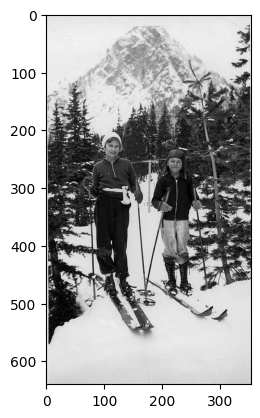

In [15]:
image = to_pil(image)
plt.imshow(image)
plt.show()